# Number theory 6: The factoring lab

*Learning path: number theory, part 6 of 7.* [Index](README.md) · Previous: [Cryptography](05-cryptography.ipynb) · Next: [The number field sieve](07-number-field-sieve.ipynb)

RSA is safe as long as nobody can factor $N = pq$ quickly. The best known method, the number field sieve, needs time
that grows like $L(1/3) = e^{1.92 (\ln N)^{1/3} (\ln \ln N)^{2/3}}$, and nobody has found anything fundamentally
better since 1990. This lesson is a laboratory for trying anyway. You will

* make **test numbers**: random semiprimes with two primes of the same size, like RSA keys,
* run every classic method on them and put the results on a **scoreboard** that measures how the cost grows,
* score **your own** factoring function the same way,
* let Galileo **search** through thousands of small factoring programs for a better one, and check honestly whether
  what it finds is real,
* **hunt for leaks**: test whether any cheap property of $N$ gives away even one bit of $p$.

Expect mostly negative results. That is the point of a lab: a claim of a new factoring method must survive numbers it
was not tuned on, and a claim of a leak must survive a correction for how many things were tried.

## 1. Test numbers

`semiprime(d, seed)` is a number with exactly $d$ digits that is the product of two random primes of about $d/2$
digits each. The same seed always gives the same number, so experiments can be repeated. `semifactors` gives the two
primes as a factorization, the same shape `factor` gives: one row per prime with its exponent, smaller first (you
would not have them in real life; the lab uses them to check answers).

In [1]:
N = semiprime(30, 1)
semifactors(30, 1)
isprime(N)

571777213143965220843759947161

> `semiprime`: A balanced semiprime N = p q with exactly that many digits, p and q primes of the same size drawn at random from the seed (default 0); the same seed always gives the same number.

[746427731226967, 1;
 766018181296783, 1]

> `semifactors` (see `semiprime`): A balanced semiprime N = p q with exactly that many digits, p and q primes of the same size drawn at random from the seed (default 0); the same seed always gives the same number.

false

> `isprime`: Whether n is prime (Miller-Rabin: certain below 3.3e24, a 20-base probable-prime test above), the next prime after n and the last one before it.

## 2. One method on one number

`labrun(method, N)` runs a method with a time limit. Its result is the split it found, again as rows [prime, exponent]
like `factor` ([] if it found nothing), and its explanation gives the **work**: the number of
multiplications modulo $N$ (roughly). Work is the same on every computer and in the browser, so it is a fair
measure; on a normal computer the time is shown too. The built-in methods are

* `"trial"`: trial division, about $\sqrt N$ steps,
* `"fermat"`: Fermat's method from lesson 2, fast only if $p$ and $q$ are very close,
* `"hart"`: Hart's one-line method (2012), about $N^{1/3}$,
* `"rho"`: Pollard's rho, about $N^{1/4}$,
* `"pm1"`: Pollard's $p - 1$, fast only when $p - 1$ is made of small primes,
* `"squfof"`: Shanks' square forms, $N^{1/4}$ with tiny numbers,
* `"classgroup"`: the class group method of Schnorr and Lenstra,
* `"ecm"`: Lenstra's elliptic curves, whose cost depends on the size of $p$,
* `"qs"`: the quadratic sieve, the fastest method for numbers below about 100 digits.

In [2]:
labrun("rho", semiprime(20, 1))
labrun("qs", semiprime(40, 1))

[6861287249, 1;
 7976458513, 1]

> rho found 7976458513 in 4.5e4 work units (30 ms)

[63949495192839526909, 1;
 74346260874176736061, 1]

> qs found 74346260874176736061 in 9.8e5 work units (188 ms)

## 3. The scoreboard

`scoreboard(methods, digits, trials, seconds)` runs each method on `trials` semiprimes of every size in `digits`, with
at most `seconds` per number, and stops a method at the first size where it solves nothing. Below each table it fits
three growth laws to the costs: $N^a$ (exponential in the number of digits), $L(1/2)$ (the quadratic sieve's law) and
$L(1/3)$ (the number field sieve's).

In [3]:
sb = scoreboard(["rho" "squfof" "ecm"], 12:4:36, 2, 1)

["rho"   , 12, 2, 2, 0.00015955450000000002;
 "rho"   , 16, 2, 2,           0.0016175395;
 "rho"   , 20, 2, 2,            0.043729875;
 "rho"   , 24, 1, 2,            0.685486577;
 "rho"   , 28, 0, 2,                      0;
 "squfof", 12, 2, 2,           0.0000412605;
 "squfof", 16, 2, 2,            0.000671816;
 "squfof", 20, 2, 2,  0.0018261755000000001;
 "squfof", 24, 2, 2,    0.09957267149999999;
 "squfof", 28, 2, 2,           0.3583325995;
 "squfof", 32, 0, 2,                      0;
 "ecm"   , 12, 2, 2,            0.014155209;
 "ecm"   , 16, 2, 2,            0.013353375;
 "ecm"   , 20, 2, 2,             0.06532818;
 "ecm"   , 24, 1, 2,            0.033961877;
 "ecm"   , 28, 1, 2,            0.555355725;
 "ecm"   , 32, 2, 2,            0.219738846;
 "ecm"   , 36, 0, 2,                      0]

> **Scoreboard**: balanced semiprimes (p and q of the same size, seeds 0 to 1), at most 1.00 s per run.
>
> | method | digits | solved | median work | median time |
> |---|---|---|---|---|
> | `rho` | 12 | 2/2 | 894 | <1 ms |
> | `rho` | 16 | 2/2 | 1.0e4 | 2 ms |
> | `rho` | 20 | 2/2 | 6.5e4 | 44 ms |
> | `rho` | 24 | 1/2 | 1.1e6 | 685 ms |
> | `rho` | 28 | 0/2 | - | - |
> | `squfof` | 12 | 2/2 | 2112 | <1 ms |
> | `squfof` | 16 | 2/2 | 3.7e4 | <1 ms |
> | `squfof` | 20 | 2/2 | 1.0e5 | 2 ms |
> | `squfof` | 24 | 2/2 | 5.7e6 | 100 ms |
> | `squfof` | 28 | 2/2 | 2.0e7 | 358 ms |
> | `squfof` | 32 | 0/2 | - | - |
> | `ecm` | 12 | 2/2 | 9660 | 14 ms |
> | `ecm` | 16 | 2/2 | 9660 | 13 ms |
> | `ecm` | 20 | 2/2 | 1.5e5 | 65 ms |
> | `ecm` | 24 | 1/2 | 5.3e4 | 34 ms |
> | `ecm` | 28 | 1/2 | 1.3e6 | 555 ms |
> | `ecm` | 32 | 2/2 | 6.4e5 | 220 ms |
> | `ecm` | 36 | 0/2 | - | - |
>
> **How the cost grows** (time; for reference: trial division N^0.5, Hart N^0.33, rho and SQUFOF N^0.25, quadratic sieve L(1/2) with constant 1, number field sieve L(1/3) with constant 1.92):
>
> - `rho`: cost grows like N^0.328 (fit on 3 sizes); L(1/2) constant 1.80, L(1/3) constant 3.38; best fit: L(1/3) (few sizes: the models are hard to tell apart)
> - `squfof`: cost grows like N^0.248 (fit on 4 sizes); L(1/2) constant 1.41, L(1/3) constant 2.67; best fit: N^a (few sizes: the models are hard to tell apart)
> - `ecm`: cost grows like N^0.075 (fit on 6 sizes); L(1/2) constant 0.42, L(1/3) constant 0.79; best fit: N^a
>
> The value has one row per method and size: method, digits, solved, trials, cost (seconds, or work units in the browser).

Rho should grow like $N^{1/4}$; the measured exponent is a bit higher because numbers above 19 digits no longer fit
in one 64-bit word, so each multiplication gets slower too. SQUFOF is close to $1/4$. ECM grows much more slowly,
because its cost depends on the size of $p$ in a sub-exponential way. The quadratic sieve has a fixed start-up cost
(building a factor base, sieving a whole interval) that hides its growth on small numbers, so it gets its own range:

In [4]:
sq = scoreboard("qs", 30:4:50, 2, 3)

["qs", 30, 2, 2,        0.0764005705;
 "qs", 34, 2, 2, 0.08762767399999999;
 "qs", 38, 2, 2,        0.1218123895;
 "qs", 42, 2, 2,         0.197587983;
 "qs", 46, 2, 2,         0.467441555;
 "qs", 50, 2, 2,        1.2018406135]

> **Scoreboard**: balanced semiprimes (p and q of the same size, seeds 0 to 1), at most 3.00 s per run.
>
> | method | digits | solved | median work | median time |
> |---|---|---|---|---|
> | `qs` | 30 | 2/2 | 1.6e5 | 76 ms |
> | `qs` | 34 | 2/2 | 2.1e5 | 88 ms |
> | `qs` | 38 | 2/2 | 5.7e5 | 122 ms |
> | `qs` | 42 | 2/2 | 1.3e6 | 198 ms |
> | `qs` | 46 | 2/2 | 4.1e6 | 467 ms |
> | `qs` | 50 | 2/2 | 9.6e6 | 1.20 s |
>
> **How the cost grows** (time; for reference: trial division N^0.5, Hart N^0.33, rho and SQUFOF N^0.25, quadratic sieve L(1/2) with constant 1, number field sieve L(1/3) with constant 1.92):
>
> - `qs`: cost grows like N^0.060 (fit on 6 sizes); L(1/2) constant 0.44, L(1/3) constant 0.91; best fit: N^a
>
> The value has one row per method and size: method, digits, solved, trials, cost (seconds, or work units in the browser).

The plot shows log₁₀ of the cost against the number of digits. A method whose cost is $N^a$ gives a straight line
with slope $a$; $L(1/2)$ and $L(1/3)$ curves bend down, because they grow more slowly than any power of $N$. The thin
reference lines all start at the first point, so you can compare slopes. With only a few sizes the three growth
laws are hard to tell apart; the slope over a wide range is the honest summary.

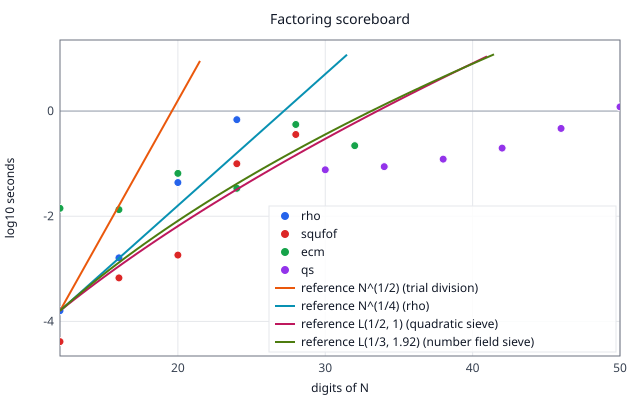

> `scoreplot`: Plots scoreboard results: log10 of the cost against the number of digits, one series of points per method, plus reference curves for N^(1/2), N^(1/4), L(1/2, 1) and L(1/3, 1.92) drawn through the first point (only where they stay near the data).

In [5]:
scoreplot(sb, sq)

## 4. Score your own method

Any function `f(n)` that returns a factor can go on the scoreboard. Here is Fermat's method from lesson 2, written in
Galileo: start at $a = \lceil \sqrt n \rceil$ and step up until $a^2 - n$ is a square $b^2$; then $n = (a - b)(a + b)$.

In [6]:
fstep(n, a) := if(isqrt(a^2 - n)^2 == a^2 - n, a - isqrt(a^2 - n), fstep(n, a + 1));
myfermat(n) := fstep(n, isqrt(n) + 1);
myfermat(8051)
scoreboard(["myfermat" "rho"], 8:2:14, 2, 1)

83

["myfermat",  8, 2, 2,            0.000122517;
 "myfermat", 10, 2, 2,            0.012384575;
 "myfermat", 12, 2, 2,            0.005009079;
 "myfermat", 14, 2, 2,            0.132245907;
 "rho"     ,  8, 2, 2,            0.000016771;
 "rho"     , 10, 2, 2,            0.000057391;
 "rho"     , 12, 2, 2, 0.00011065100000000001;
 "rho"     , 14, 2, 2,  0.0006673135000000001]

> **Scoreboard**: balanced semiprimes (p and q of the same size, seeds 0 to 1), at most 1.00 s per run.
>
> | method | digits | solved | median work | median time |
> |---|---|---|---|---|
> | `myfermat` | 8 | 2/2 | 488 | <1 ms |
> | `myfermat` | 10 | 2/2 | 5.5e4 | 12 ms |
> | `myfermat` | 12 | 2/2 | 2.1e4 | 5 ms |
> | `myfermat` | 14 | 2/2 | 5.7e5 | 132 ms |
> | `rho` | 8 | 2/2 | 190 | <1 ms |
> | `rho` | 10 | 2/2 | 638 | <1 ms |
> | `rho` | 12 | 2/2 | 894 | <1 ms |
> | `rho` | 14 | 2/2 | 4862 | <1 ms |
>
> **How the cost grows** (time; for reference: trial division N^0.5, Hart N^0.33, rho and SQUFOF N^0.25, quadratic sieve L(1/2) with constant 1, number field sieve L(1/3) with constant 1.92):
>
> - `myfermat`: cost grows like N^0.257 (fit on 3 sizes); L(1/2) constant 1.11, L(1/3) constant 1.91; best fit: N^a (few sizes: the models are hard to tell apart)
> - `rho`: cost grows like N^0.254 (fit on 4 sizes); L(1/2) constant 1.07, L(1/3) constant 1.83; best fit: N^a (few sizes: the models are hard to tell apart)
>
> The value has one row per method and size: method, digits, solved, trials, cost (seconds, or work units in the browser).

For your own functions, work counts evaluation steps of the Galileo program, so compare them by time on a computer.
Fermat dies quickly on balanced semiprimes: $p$ and $q$ are of the same size but not close, and the number of steps
grows like $(q - p)^2 / \sqrt N$.

## 5. Factoring programs

To search for new methods, Galileo needs a language in which a method is small enough to generate at random. It has
two kinds of programs.

**`iter(f, h, x0)`**: start with $x = x_0$ and at every step $i$ replace $x$ by $f(x, y, i)$ modulo $N$, where $y$ is
the value of $x$ at the last step that was a power of 2. Multiply up the values $h$ and check $\gcd(\cdot, N)$ every
32 steps. Pollard's rho is `iter(x^2 + 1, x - y, 2)`: the sequence $x^2 + 1$ repeats modulo $p$ long before it repeats
modulo $N$, and $x - y$ then has the factor $p$. Pollard's $p - 1$ is `iter(pow(x, i), x - 1, 2)`: $x$ becomes
$2^{i!}$.

**`rel(s, fb)`**: at step $i$ compute $s$ and $r = s^2 \bmod N$ (between $-N/2$ and $N/2$). If $r = t^2$ is a square,
then $s^2 \equiv t^2$ and $\gcd(s - t, N)$ is often a factor. With a factor base of `fb` small primes, every $r$ that
splits completely over them is kept, and linear algebra modulo 2 multiplies some of them into a square: this is
Dixon's method, the idea behind the quadratic sieve. Fermat is `rel(rt + i, 0)` and Hart's method is `rel(rti, 0)`.

The names are `x`, `y`, `i`, `rt` $= \lceil\sqrt N\rceil$, `rti` $= \lceil\sqrt{iN}\rceil$, `B` $= \lfloor N^{1/3}\rfloor$,
`d0`, `d1` (the last two digits of $N$ in base $B$) and small integers; the operations are `+ - *`, powers `a^k`,
`pow(a, i)`, `luc(a)` (the Lucas sequence $V_i(a)$, Williams' $p + 1$ method) and `inv(a)` (an inverse modulo $N$;
when it does not exist, $\gcd(a, N)$ is a factor, the trick behind ECM).

In [7]:
N = semiprime(18, 4);
labrun("iter(x^2 + 1, x - y, 2)", N)
labrun("iter(x^2 - 2, x - y, 2)", N, 0.5)
labrun("rel(rti, 64)", N)

[554328583, 1;
 794513963, 1]

> iter(x^2 + 1, x - y, 2) found 794513963 in 1.1e5 work units (2 ms)

[]

> iter(x^2 - 2, x - y, 2) found no factor of 440421799283504429 in 73 work units (<1 ms)

[554328583, 1;
 794513963, 1]

> rel(rti, 64) found 554328583 in 1.5e7 work units (295 ms)

`iter(x^2 - 2, x - y, 2)` fails at once: $2^2 - 2 = 2$, so the sequence never moves and $x - y$ is always 0. Even
with another start, $x^2 - 2$ is a famous bad choice: with $x = u + 1/u$ it becomes $u^2 + 1/u^2$, so the sequence is
$u^{2^i} + u^{-2^i}$ and behaves like a power map instead of a random one. (The search below rediscovers why the
constant matters.) Programs go on the scoreboard like any method:

In [8]:
scoreboard(["iter(x^2 + 1, x - y, 2)" "iter(x^4 + 1, x - y, 2)" "rel(rti, 64)"], 12:2:18, 3, 1)

["iter(x^2 + 1, x - y, 2)", 12, 3, 3, 0.000061945;
 "iter(x^2 + 1, x - y, 2)", 14, 3, 3, 0.000066343;
 "iter(x^2 + 1, x - y, 2)", 16, 3, 3, 0.000443979;
 "iter(x^2 + 1, x - y, 2)", 18, 3, 3, 0.000831379;
 "iter(x^4 + 1, x - y, 2)", 12, 3, 3, 0.000063572;
 "iter(x^4 + 1, x - y, 2)", 14, 3, 3,  0.00013738;
 "iter(x^4 + 1, x - y, 2)", 16, 3, 3, 0.000349213;
 "iter(x^4 + 1, x - y, 2)", 18, 3, 3, 0.000288834;
 "rel(rti, 64)"           , 12, 3, 3, 0.000785929;
 "rel(rti, 64)"           , 14, 3, 3, 0.002438082;
 "rel(rti, 64)"           , 16, 3, 3, 0.013216752;
 "rel(rti, 64)"           , 18, 3, 3, 0.091427171]

> **Scoreboard**: balanced semiprimes (p and q of the same size, seeds 0 to 2), at most 1.00 s per run.
>
> | method | digits | solved | median work | median time |
> |---|---|---|---|---|
> | `iter(x^2 + 1, x - y, 2)` | 12 | 3/3 | 3468 | <1 ms |
> | `iter(x^2 + 1, x - y, 2)` | 14 | 3/3 | 3740 | <1 ms |
> | `iter(x^2 + 1, x - y, 2)` | 16 | 3/3 | 2.3e4 | <1 ms |
> | `iter(x^2 + 1, x - y, 2)` | 18 | 3/3 | 4.4e4 | <1 ms |
> | `iter(x^4 + 1, x - y, 2)` | 12 | 3/3 | 3600 | <1 ms |
> | `iter(x^4 + 1, x - y, 2)` | 14 | 3/3 | 1.0e4 | <1 ms |
> | `iter(x^4 + 1, x - y, 2)` | 16 | 3/3 | 2.5e4 | <1 ms |
> | `iter(x^4 + 1, x - y, 2)` | 18 | 3/3 | 2.1e4 | <1 ms |
> | `rel(rti, 64)` | 12 | 3/3 | 2.0e4 | <1 ms |
> | `rel(rti, 64)` | 14 | 3/3 | 1.5e5 | 2 ms |
> | `rel(rti, 64)` | 16 | 3/3 | 7.2e5 | 13 ms |
> | `rel(rti, 64)` | 18 | 3/3 | 4.6e6 | 91 ms |
>
> **How the cost grows** (time; for reference: trial division N^0.5, Hart N^0.33, rho and SQUFOF N^0.25, quadratic sieve L(1/2) with constant 1, number field sieve L(1/3) with constant 1.92):
>
> - `iter(x^2 + 1, x - y, 2)`: cost grows like N^0.210 (fit on 4 sizes); L(1/2) constant 1.02, L(1/3) constant 1.82; best fit: N^a (few sizes: the models are hard to tell apart)
> - `iter(x^4 + 1, x - y, 2)`: cost grows like N^0.119 (fit on 4 sizes); L(1/2) constant 0.58, L(1/3) constant 1.05; best fit: L(1/3) (few sizes: the models are hard to tell apart)
> - `rel(rti, 64)`: cost grows like N^0.347 (fit on 4 sizes); L(1/2) constant 1.68, L(1/3) constant 3.00; best fit: N^a (few sizes: the models are hard to tell apart)
>
> The value has one row per method and size: method, digits, solved, trials, cost (seconds, or work units in the browser).

## 6. Searching for a better algorithm

`algosearch(seconds, mode)` generates programs and scores them by the total work on a fixed **training set** of 12
semiprimes with 12 to 18 digits. A program that misses a number is charged 8 times the limit. Modes:

* `"evolve"` (default): start from random programs, keep the best, mutate them (replace a piece, change a constant,
  switch between `iter` and `rel`) and recombine pieces of two good ones,
* `"random"`: just random programs, the baseline any clever search must beat,
* `"exhaustive"`: every program in order of size, the brute-force search.

Programs that compute the same values on a test modulus are scored only once. At the end, the best five are run on a
**held-out set** of 24 other semiprimes, one size larger than any in training, next to Pollard rho, and a paired
test gives a p-value for the difference.

In [9]:
r = algosearch(10)

["iter((x + ((-1) + x^2))^3, x - y, 5)";
 "iter((25 + (x + x^2))^3, x - y, 5)";
 "iter((x + ((-1) + x^2))^3, x - y, 12)";
 "iter((25 + x)^6, x - y, 5)";
 "grp(quad(-1), i + x, 0)";
 "grp(quad(-1), i, 0)";
 "iter((25 + ((-1) + x))^3, x - y, 3)";
 "iter((25 + ((-1) + x))^3, x - y, 2)"]

> **Algorithm search** (evolve, seed 1): 240 programs scored, 257 distinct candidates generated, 10.1 s.
>
> Training set: 12 balanced semiprimes of 12, 14, 16, 18 digits; work is counted in multiplications mod N; a miss costs 8 times the cap. The best programs are then re-run on 24 numbers the search never saw (14, 16, 18, 20 digits), next to Pollard rho.
>
> | program | solved (training) | work vs rho (training) | solved (held out) | work vs rho (held out) | p-value |
> |---|---|---|---|---|---|
> | `iter((x + ((-1) + x^2))^3, x - y, 5)` | 12/12 | 1.26x less | 24/24 | 0.81x less | 0.378 |
> | `iter((25 + (x + x^2))^3, x - y, 5)` | 12/12 | 1.18x less | 24/24 | 0.60x less | 0.036 |
> | `iter((x + ((-1) + x^2))^3, x - y, 12)` | 12/12 | 0.90x less | 24/24 | 0.73x less | 0.224 |
> | `iter((25 + x)^6, x - y, 5)` | 12/12 | 0.86x less | 24/24 | 0.73x less | 0.182 |
> | `grp(quad(-1), i + x, 0)` | 12/12 | 0.61x less | 11/24 | 0.10x less | 6.4e-5 |
> | `grp(quad(-1), i, 0)` | 12/12 | 0.61x less | - | - | - |
> | `iter((25 + ((-1) + x))^3, x - y, 3)` | 10/12 | 0.50x less | - | - | - |
> | `iter((25 + ((-1) + x))^3, x - y, 2)` | 10/12 | 0.47x less | - | - | - |
>
> For comparison, the classics on the same training set:
>
> | classic | program | solved | work vs rho |
> |---|---|---|---|
> | Pollard rho | `iter(x^2 + 1, x - y, 2)` | 12/12 | 1.00x less |
> | Pollard p - 1 | `iter(pow(x, i), x - 1, 2)` | 10/12 | 0.40x less |
> | Williams p + 1 | `iter(luc(x), x - 2, 3)` | 9/12 | 0.20x less |
> | Fermat | `rel(rt + i, 0)` | 4/12 | 0.08x less |
> | Hart one-line | `rel(rti, 0)` | 6/12 | 0.07x less |
> | Dixon near sqrt(N) | `rel(rt + i, 64)` | 3/12 | 0.03x less |
> | Dixon near sqrt(iN) | `rel(rti, 64)` | 4/12 | 0.03x less |
> | p - 1 as a group program | `grp(mul, i, 0)` | 10/12 | 0.41x less |
> | p + 1 side (a + b sqrt(-1)) | `grp(quad(-1), i, 0)` | 12/12 | 0.61x less |
> | cyclotomic Phi_3 (Bach-Shallit) | `grp(cubic(2), i, 0)` | 0/12 | 0.01x less |
> | 2 x 2 matrices | `grp(mat, i, 0)` | 4/12 | 0.03x less |
> | ECM, 100 steps per curve | `grp(ec(3), i, 100)` | 9/12 | 0.27x less |
>
> **Verdict**: nothing beats Pollard rho on numbers the search did not train on: the best held-out ratio is 0.81x (`iter((x + ((-1) + x^2))^3, x - y, 5)`, p = 0.378, and 5 programs were tested, so a p-value above 0.01 is what chance gives). Gains on the training set are mostly luck: rho's cost varies a lot from number to number, and a search that tries thousands of variants finds some that were lucky on those 12 numbers.
>
> r[k] is program k as text: scoreboard(r[0], 12:2:22) runs it on bigger numbers. leaderboard() keeps the best programs of all searches in this session.

Look at the two "work vs rho" columns. On the training numbers the winners look up to about twice as fast as rho. On the
held-out numbers the advantage disappears. This is **overfitting**: the cost of rho on one number is very random (it
depends on when a sequence happens to repeat modulo $p$), and among thousands of variants of $x \mapsto x^2 + c$ some
are lucky on exactly those 12 numbers. The search does rediscover the classics on its own: quadratic and quartic maps
$x \mapsto (x + c)^2 + \ldots$ with `x - y` (rho), and sometimes `pow(x, i)` ($p - 1$). Longer runs on a computer
(`algosearch(300)`) find the same kinds of programs.

The brute-force search finds the same thing in its own way: the first programs that work at all are rho with small
constants.

In [10]:
algosearch(5, "exhaustive")

["grp(quad(-1), i, 0)";
 "grp(mul, i, 0)";
 "grp(ec(3), i, 100)";
 "grp(quad(3), i, 0)";
 "grp(ec(6), i, 100)";
 "grp(quad(2), i, 0)";
 "grp(ec(5), i, 100)";
 "grp(ec(3), i, 30)"]

> **Algorithm search** (exhaustive, seed 1): 128 programs scored, 136 distinct candidates generated, 5.0 s.
>
> Training set: 12 balanced semiprimes of 12, 14, 16, 18 digits; work is counted in multiplications mod N; a miss costs 8 times the cap. The best programs are then re-run on 24 numbers the search never saw (14, 16, 18, 20 digits), next to Pollard rho.
>
> | program | solved (training) | work vs rho (training) | solved (held out) | work vs rho (held out) | p-value |
> |---|---|---|---|---|---|
> | `grp(quad(-1), i, 0)` | 12/12 | 0.61x less | 11/24 | 0.10x less | 6.5e-5 |
> | `grp(mul, i, 0)` | 10/12 | 0.41x less | 14/24 | 0.25x less | 0.027 |
> | `grp(ec(3), i, 100)` | 9/12 | 0.27x less | 12/24 | 0.08x less | 2.2e-6 |
> | `grp(quad(3), i, 0)` | 8/12 | 0.18x less | 12/24 | 0.11x less | 7.5e-5 |
> | `grp(ec(6), i, 100)` | 9/12 | 0.13x less | 14/24 | 0.08x less | 6.5e-7 |
> | `grp(quad(2), i, 0)` | 7/12 | 0.13x less | - | - | - |
> | `grp(ec(5), i, 100)` | 9/12 | 0.12x less | - | - | - |
> | `grp(ec(3), i, 30)` | 7/12 | 0.10x less | - | - | - |
>
> For comparison, the classics on the same training set:
>
> | classic | program | solved | work vs rho |
> |---|---|---|---|
> | Pollard rho | `iter(x^2 + 1, x - y, 2)` | 12/12 | 1.00x less |
> | Pollard p - 1 | `iter(pow(x, i), x - 1, 2)` | 10/12 | 0.40x less |
> | Williams p + 1 | `iter(luc(x), x - 2, 3)` | 9/12 | 0.20x less |
> | Fermat | `rel(rt + i, 0)` | 4/12 | 0.08x less |
> | Hart one-line | `rel(rti, 0)` | 6/12 | 0.07x less |
> | Dixon near sqrt(N) | `rel(rt + i, 64)` | 3/12 | 0.03x less |
> | Dixon near sqrt(iN) | `rel(rti, 64)` | 4/12 | 0.03x less |
> | p - 1 as a group program | `grp(mul, i, 0)` | 10/12 | 0.41x less |
> | p + 1 side (a + b sqrt(-1)) | `grp(quad(-1), i, 0)` | 12/12 | 0.61x less |
> | cyclotomic Phi_3 (Bach-Shallit) | `grp(cubic(2), i, 0)` | 0/12 | 0.01x less |
> | 2 x 2 matrices | `grp(mat, i, 0)` | 4/12 | 0.03x less |
> | ECM, 100 steps per curve | `grp(ec(3), i, 100)` | 9/12 | 0.27x less |
>
> **Verdict**: nothing beats Pollard rho on numbers the search did not train on: the best held-out ratio is 0.25x (`grp(mul, i, 0)`, p = 0.027, and 5 programs were tested, so a p-value above 0.01 is what chance gives). Gains on the training set are mostly luck: rho's cost varies a lot from number to number, and a search that tries thousands of variants finds some that were lucky on those 12 numbers.
>
> r[k] is program k as text: scoreboard(r[0], 12:2:22) runs it on bigger numbers. leaderboard() keeps the best programs of all searches in this session.

`leaderboard()` collects the best programs of every search in this session. To test a candidate seriously, put it on
the scoreboard at sizes it never saw: `scoreboard(r[0], 12:2:24, 6, 2)`.

In [11]:
leaderboard()

["iter((x + ((-1) + x^2))^3, x - y, 5)";
 "iter((x + ((-1) + x^2))^3, x - y, 12)";
 "iter((25 + x)^6, x - y, 5)";
 "iter((25 + (x + x^2))^3, x - y, 5)";
 "grp(mul, i, 0)";
 "grp(quad(3), i, 0)";
 "grp(quad(-1), i, 0)";
 "grp(quad(-1), i + x, 0)";
 "grp(ec(6), i, 100)";
 "grp(ec(3), i, 100)";
 "iter((25 + ((-1) + x))^3, x - y, 3)";
 "iter((25 + ((-1) + x))^3, x - y, 2)";
 "grp(mul, i + x, 0)";
 "iter((25 + x)^3, x - y, 5)";
 "grp(quad(-1), 6*(11 + i), 0)"]

> **Leaderboard** of this session (checked programs first, by how much less work than rho they need on numbers no search trained on)
>
> | # | program | training digits | training score | held out vs rho | p-value | found by |
> |---|---|---|---|---|---|---|
> | 0 | `iter((x + ((-1) + x^2))^3, x - y, 5)` | 12-18 | 160.0 | 0.81x less work | 0.378 | evolve |
> | 1 | `iter((x + ((-1) + x^2))^3, x - y, 12)` | 12-18 | 165.8 | 0.73x less work | 0.224 | evolve |
> | 2 | `iter((25 + x)^6, x - y, 5)` | 12-18 | 166.5 | 0.73x less work | 0.182 | evolve |
> | 3 | `iter((25 + (x + x^2))^3, x - y, 5)` | 12-18 | 161.2 | 0.60x less work | 0.036 | evolve |
> | 4 | `grp(mul, i, 0)` | 12-18 | 179.6 | 0.25x less work | 0.027 | exhaustive |
> | 5 | `grp(quad(3), i, 0)` | 12-18 | 193.8 | 0.11x less work | 7.5e-5 | exhaustive |
> | 6 | `grp(quad(-1), i, 0)` | 12-18 | 172.6 | 0.10x less work | 6.5e-5 | exhaustive |
> | 7 | `grp(quad(-1), i + x, 0)` | 12-18 | 172.6 | 0.10x less work | 6.4e-5 | evolve |
> | 8 | `grp(ec(6), i, 100)` | 12-18 | 199.5 | 0.08x less work | 6.5e-7 | exhaustive |
> | 9 | `grp(ec(3), i, 100)` | 12-18 | 186.8 | 0.08x less work | 2.2e-6 | exhaustive |
> | 10 | `iter((25 + ((-1) + x))^3, x - y, 3)` | 12-18 | 176.1 | - | - | evolve |
> | 11 | `iter((25 + ((-1) + x))^3, x - y, 2)` | 12-18 | 177.0 | - | - | evolve |
> | 12 | `grp(mul, i + x, 0)` | 12-18 | 179.6 | - | - | evolve |
> | 13 | `iter((25 + x)^3, x - y, 5)` | 12-18 | 179.7 | - | - | evolve |
> | 14 | `grp(quad(-1), 6*(11 + i), 0)` | 12-18 | 180.1 | - | - | evolve |

Why can't the search find something like the quadratic sieve? It can express Dixon's method (`rel(rti, 64)`), whose
cost grows only like $L(1/2)$, but at 12 to 18 digits rho is still faster: sub-exponential methods only win on big
numbers. A search scored on small numbers prefers rho; one scored on 40-digit numbers would need far more time per
program. That is a real lesson about algorithm search: the training sizes decide what it can discover.

## 7. Hunting for leaks

If some cheap property of $N$ told us one bit of $p$, that would be a start. `leakhunt(digits, samples, seed)` makes
semiprimes with known factors and computes about 45 features of $N$: residues $N \bmod m$, Jacobi symbols $(a/N)$,
leading digits, digits in base 3 and 7, the bit count, the fractional part of $\sqrt N$, the first terms and the period
of the continued fraction of $\sqrt N$, and for small $N$ the class number $h(-4N)$. Each feature is tested against
properties of the smaller prime $p$ with a chi-squared test of independence on the first half of the samples. With
about 500 tests, some p-values below 0.01 appear by chance alone, so they are corrected (Benjamini–Hochberg) and the
best one per property is tested again on the second half. Finally a naive Bayes classifier combines all features to
predict each property; its accuracy is compared with always guessing the more common answer.

Three properties are **controls** that must leak: $p \equiv q \pmod 3$ is decided by $N \bmod 3$ (if $N \equiv 1$ then
$p \equiv q$), the same for mod 4, and the second bit of $p$ depends on how big $N$ is (a small $N$ needs a small $p$).
If the controls did not show up, the test would be broken.

In [12]:
leakhunt(14, 4000)

["leading digit of N"                 , "second bit of p (below the leading 1)", 5.779574233630868e-145, 2.2022075183760655e-134;
 "N mod 4"                            , "p = q (mod 4)"                        ,                    0.0,                     0.0;
 "N mod 3"                            , "p = q (mod 3)"                        ,                    0.0,                     0.0;
 "N mod 8"                            , "p = q (mod 4)"                        ,                    0.0,                     0.0;
 "N mod 12"                           , "p = q (mod 4)"                        ,                    0.0,                     0.0;
 "N mod 16"                           , "p = q (mod 4)"                        ,                    0.0,                     0.0;
 "N mod 24"                           , "p = q (mod 4)"                        ,                    0.0,                     0.0;
 "N mod 32"                           , "p = q (mod 4)"                        ,          

> **Leakage hunt**: 4000 balanced semiprimes N = p q of 14 digits (p the smaller prime). 46 features of N against 11 properties of p: 506 tests on the first half, the best per property re-tested on the second half. Properties marked *control* are known to depend on N and show that the test can see a leak.
>
> | property of p | best feature of N | p-value | corrected (BH) | held-out p-value | naive Bayes accuracy (chance) | p-value |
> |---|---|---|---|---|---|---|
> | p = 1 (mod 4) | N mod 31 | 0.048 | 0.672 | 0.805 | 49.3% (51.0%) | 0.933 |
> | p = 1 (mod 3) | CF of sqrt N: a2 mod 4 | 0.002 | 0.067 | 0.842 | 48.1% (50.4%) | 0.983 |
> | p = +-1 (mod 8) | CF of sqrt N: a3 mod 4 | 0.021 | 0.418 | 0.029 | 49.5% (50.6%) | 0.820 |
> | p = +-1 (mod 5) | popcount(N) mod 2 | 0.118 | 0.875 | 0.719 | 50.4% (50.1%) | 0.403 |
> | middle bit of p | Jacobi (11/N) | 0.040 | 0.650 | 0.382 | 49.3% (50.8%) | 0.921 |
> | lowest bit of floor(p / 10) | N mod 37 | 0.005 | 0.145 | 0.074 | 50.5% (50.1%) | 0.369 |
> | popcount(p) odd | N mod 8 | 0.009 | 0.238 | 0.257 | 50.9% (51.4%) | 0.697 |
> | second bit of p (below the leading 1) (control) | leading digit of N | 1.6e-146 | 5.8e-145 | 2.2e-134 | 72.8% (51.4%) | 3.5e-85 |
> | p = q (mod 4) (control) | N mod 4 | < 1e-300 | < 1e-300 | < 1e-300 | 100.0% (51.6%) | < 1e-300 |
> | p = q (mod 3) (control) | N mod 3 | < 1e-300 | < 1e-300 | < 1e-300 | 100.0% (50.6%) | < 1e-300 |
> | Legendre (p/q) = 1 (control) | N mod 30 | 0.012 | 0.296 | 0.337 | 48.9% (50.8%) | 0.961 |
>
> **Verdict**: no feature predicts any property of p alone better than chance after correcting for 506 tests, and combining all features does not either. The controls do show up, so the test would have seen a leak of that strength.
>
> The value lists the significant pairs: feature, property of p, corrected p-value, held-out p-value.

The controls light up with p-values far below $10^{-100}$, so the test is sensitive. Nothing else survives the
correction and the held-out check: no residue, digit pattern or continued fraction term of $N$ says anything about
$p \bmod 4$, $p \bmod 3$, a middle bit or the bit count of $p$, and the naive Bayes accuracy for those stays at chance.
Runs with 20000 numbers of 16 digits and 10000 of 30 digits on a computer give the same answer.

Small numbers are a trap. With 6 digits, $p$ is one of only about a hundred primes between 317 and 1000, so the
leading digits of $N$ already say roughly how big $p$ is, and within such a short list, size, residues and bits of
$p$ are tangled up. Everything seems to leak:

In [13]:
leakhunt(6, 3000)

["CF of sqrt N: period length mod 4 (3 = longer than 4000)", "p = 1 (mod 4)"                        ,   4.599615011712233e-74,  1.6209394542632437e-76;
 "class number h(-4N) mod 8"                               , "p = +-1 (mod 8)"                      ,    9.298497540346732e-9,   1.4245481144764754e-8;
 "N mod 5"                                                 , "p = +-1 (mod 5)"                      ,   3.7187830112262757e-6,    4.249532156351502e-6;
 "zero digits of N in base 3, mod 2"                       , "middle bit of p"                      ,     0.03152338177869049,      0.7562392381584977;
 "leading digit of N in base 7"                            , "lowest bit of floor(p / 10)"          ,    0.015673355113157785,    0.007456444413981296;
 "leading digit of N in base 7"                            , "popcount(p) odd"                      ,  0.00017170864094255848,   7.128465650406966e-13;
 "leading digit of N"                                      , "second bit of p (below the

> **Leakage hunt**: 3000 balanced semiprimes N = p q of 6 digits (p the smaller prime). 49 features of N against 11 properties of p: 539 tests on the first half, the best per property re-tested on the second half. Properties marked *control* are known to depend on N and show that the test can see a leak.
>
> | property of p | best feature of N | p-value | corrected (BH) | held-out p-value | naive Bayes accuracy (chance) | p-value |
> |---|---|---|---|---|---|---|
> | p = 1 (mod 4) | CF of sqrt N: period length mod 4 (3 = longer than 4000) | 1.3e-75 | 4.6e-74 | 1.6e-76 | 66.5% (51.5%) | 4.8e-32 |
> | p = 1 (mod 3) | Jacobi (11/N) | 0.006 | 0.074 | 4.3e-6 | 54.8% (50.1%) | 1.6e-4 |
> | p = +-1 (mod 8) | class number h(-4N) mod 8 | 3.8e-10 | 9.3e-9 | 1.4e-8 | 54.5% (52.5%) | 0.064 |
> | p = +-1 (mod 5) | N mod 5 | 1.7e-7 | 3.7e-6 | 4.2e-6 | 55.9% (54.9%) | 0.242 |
> | middle bit of p | zero digits of N in base 3, mod 2 | 0.002 | 0.032 | 0.756 | 53.5% (53.1%) | 0.369 |
> | lowest bit of floor(p / 10) | leading digit of N in base 7 | 0.001 | 0.016 | 0.007 | 54.1% (52.9%) | 0.169 |
> | popcount(p) odd | leading digit of N in base 7 | 9.9e-6 | 1.7e-4 | 7.1e-13 | 58.3% (63.3%) | 1.000 |
> | second bit of p (below the leading 1) (control) | leading digit of N | 3.7e-79 | 1.4e-77 | 1.0e-76 | 68.3% (57.5%) | 8.5e-18 |
> | p = q (mod 4) (control) | N mod 4 | < 1e-300 | < 1e-300 | < 1e-300 | 100.0% (51.9%) | < 1e-300 |
> | p = q (mod 3) (control) | N mod 3 | < 1e-300 | < 1e-300 | < 1e-300 | 100.0% (52.5%) | < 1e-300 |
> | Legendre (p/q) = 1 (control) | class number h(-4N) mod 8 | 1.0e-45 | 3.0e-44 | 3.7e-58 | 68.9% (54.7%) | 1.1e-29 |
>
> **Small numbers**: with 6 digits there are only a few hundred primes of the size of p, so N almost pins p down and nearly every feature of N says something about it (its leading digits say how big p is, and in a short range of primes, size and residues are not independent). Leaks found here do not carry over to large N; use 10 digits or more for real conclusions.
>
> **Verdict**: p = 1 (mod 4) depends on CF of sqrt N: period length mod 4 (3 = longer than 4000) (corrected p = 4.6e-74, held-out p = 1.6e-76), but computing this feature takes about sqrt(N) steps, more than factoring N with rho. p = +-1 (mod 8) depends on class number h(-4N) mod 8 (corrected p = 9.3e-9, held-out p = 1.4e-8), but computing this feature takes about sqrt(N) steps, more than factoring N with rho. p = +-1 (mod 5) depends on N mod 5 (corrected p = 3.7e-6, held-out p = 4.2e-6). lowest bit of floor(p / 10) depends on leading digit of N in base 7 (corrected p = 0.016, held-out p = 0.007). popcount(p) odd depends on leading digit of N in base 7 (corrected p = 1.7e-4, held-out p = 7.1e-13). p = +-1 (mod 5) depends on N mod 30 (corrected p = 5.2e-6, held-out p = 2.4e-5). p = +-1 (mod 5) depends on Jacobi (5/N) (corrected p = 1.4e-5, held-out p = 2.1e-7). p = 1 (mod 4) depends on class number h(-4N) mod 8 (corrected p = 2.2e-4, held-out p = 1.9e-5), but computing this feature takes about sqrt(N) steps, more than factoring N with rho. popcount(p) odd depends on leading digit of N (corrected p = 8.8e-4, held-out p = 8.6e-10). p = +-1 (mod 5) depends on leading digit of N (corrected p = 8.8e-4, held-out p = 3.4e-4). p = +-1 (mod 8) depends on CF of sqrt N: period length mod 4 (3 = longer than 4000) (corrected p = 0.001, held-out p = 4.5e-6), but computing this feature takes about sqrt(N) steps, more than factoring N with rho. p = 1 (mod 4) depends on leading digit of N in base 7 (corrected p = 0.002, held-out p = 3.0e-5). p = +-1 (mod 8) depends on leading digit of N (corrected p = 0.003, held-out p = 0.003). p = +-1 (mod 5) depends on leading digit of N in base 7 (corrected p = 0.024, held-out p = 2.4e-4). lowest bit of floor(p / 10) depends on leading digit of N (corrected p = 0.037, held-out p = 5.3e-6). p = 1 (mod 4) depends on leading digit of N (corrected p = 0.040, held-out p = 2.5e-4). All features together predict p = 1 (mod 4) at 66.5% against 51.5% by chance (p = 4.8e-32). All features together predict p = 1 (mod 3) at 54.8% against 50.1% by chance (p = 1.6e-4). Before calling this a leak, check whether it only reflects the size of N (p is the smaller factor; with few digits, p ranges over a short interval and its bits depend on its size) and repeat with another seed and more digits.
>
> The value lists the significant pairs: feature, property of p, corrected p-value, held-out p-value.

Two of these are real mathematics, though. The class number $h(-4N)$ catches the Legendre symbol $(p/q)$: that is
genus theory (Gauss, 1801) and Rédei (1934), the 2-part of the class group of discriminant $-4pq$ depends on $(p/q)$
and on $p, q \bmod 4$. And the length of the period of the continued fraction of $\sqrt N$ tells something about
$p \bmod 4$: an odd period means $N$ is a sum of two squares, which happens only when $p \equiv q \equiv 1 \pmod 4$.
Both features are honest leaks for any size of $N$, but computing them takes about $\sqrt N$ steps, far more than
factoring $N$ with rho. The other "leaks" at 6 digits are the size effect and disappear at 10 digits and more.

## Summary

* `semiprime(d, seed)`, `semifactors(d, seed)`: reproducible RSA-like test numbers.
* `labrun(method, N)`: one run with its work; methods `trial fermat hart rho pm1 squfof classgroup ecm qs`, programs
  `iter(f, h, x0)` and `rel(s, fb)`, or your own function.
* `scoreboard(methods, digits, trials, seconds)` and `scoreplot`: how the cost grows, fitted to $N^a$, $L(1/2)$,
  $L(1/3)$.
* `algosearch(seconds, mode)`, `leaderboard()`: search for factoring programs; trust only held-out results.
* `leakhunt(digits, samples)`: features of $N$ against bits of $p$, with corrected p-values and controls.

**Try it:** add a primitive idea of your own as a Galileo function and put it on the scoreboard against `"rho"`.
Run `algosearch(60, "random")` and `algosearch(60)` with the same budget: does evolution beat random sampling? Change
the seed of `leakhunt` and check that the controls stay and the rest stays quiet. Can you think of a feature of $N$
that is cheap to compute and that the hunt does not test yet?

## Sources

1. J. M. Pollard, "A Monte Carlo method for factorization", *BIT* 15 (1975) 331–334; "Theorems on factorization and primality testing", *Proc. Cambridge Phil. Soc.* 76 (1974) 521–528.
2. R. P. Brent, "An improved Monte Carlo factorization algorithm", *BIT* 20 (1980) 176–184.
3. W. B. Hart, "A one line factoring algorithm", *J. Aust. Math. Soc.* 92 (2012) 61–69.
4. J. E. Gower and S. S. Wagstaff, "Square form factorization", *Math. Comp.* 77 (2008) 551–588.
5. C. P. Schnorr and H. W. Lenstra, "A Monte Carlo factoring algorithm with linear storage", *Math. Comp.* 43 (1984) 289–311.
6. H. W. Lenstra, "Factoring integers with elliptic curves", *Annals of Math.* 126 (1987) 649–673.
7. C. Pomerance, "The quadratic sieve factoring algorithm", *EUROCRYPT '84*, LNCS 209 (1985) 169–182.
8. R. Crandall and C. Pomerance, *Prime Numbers: A Computational Perspective*, 2nd ed., Springer (2005), chapters 5 and 6.
9. Y. Benjamini and Y. Hochberg, "Controlling the false discovery rate", *J. Royal Stat. Soc. B* 57 (1995) 289–300.
10. L. Rédei, "Arithmetischer Beweis des Satzes über die Anzahl der durch vier teilbaren Invarianten der absoluten Klassengruppe im quadratischen Zahlkörper", *J. reine angew. Math.* 171 (1934) 55–60.